In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")

In [3]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

In [5]:
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [6]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


# Handle Missing Values

In [7]:
df = df.dropna(subset=["Loan_Approved"])
df.shape

(950, 20)

In [8]:
categorical_cols = df.select_dtypes(exclude=["number"]).columns
numerical_cols = df.select_dtypes(include=["number"]).columns

In [9]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy="mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

In [10]:
cat_imp = SimpleImputer(strategy="most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

In [11]:
df.head()
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA - exploratory data analysis

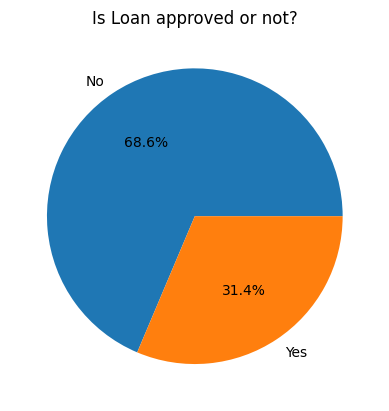

In [12]:

classes_count = df["Loan_Approved"].value_counts()

plt.pie(classes_count, labels=classes_count.index, autopct="%1.1f%%")
plt.title("Is Loan approved or not?")
plt.show()

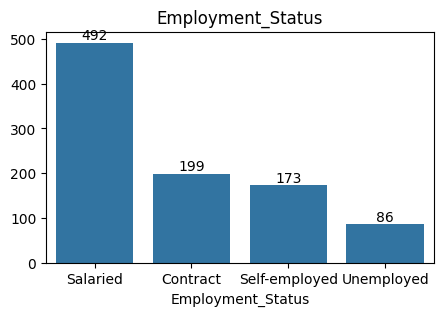

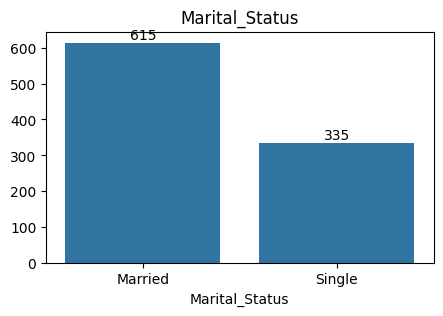

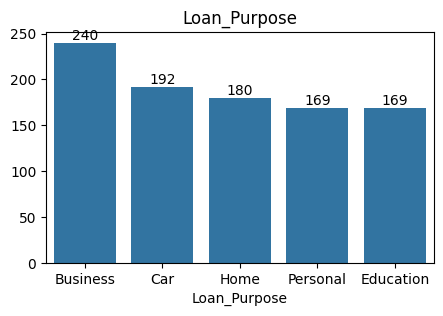

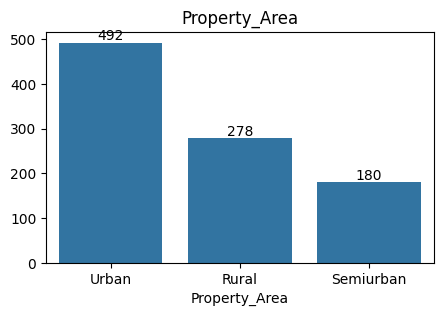

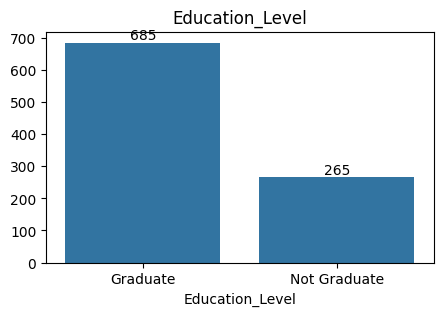

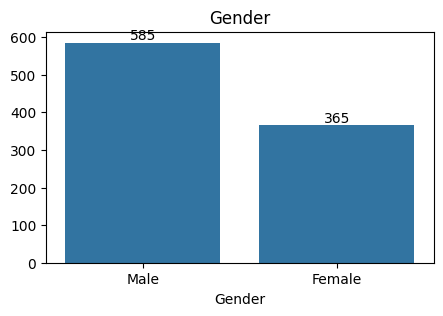

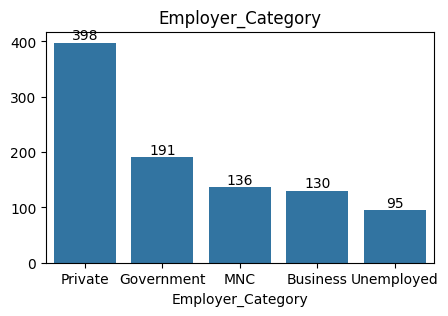

In [13]:

for col in categorical_cols.drop("Loan_Approved"):
    cnt = df[col].value_counts()
    plt.figure(figsize=(5, 3))
    ax = sns.barplot(x=cnt.index, y=cnt.values)
    ax.bar_label(ax.containers[0])
    plt.title(col)
    plt.show()

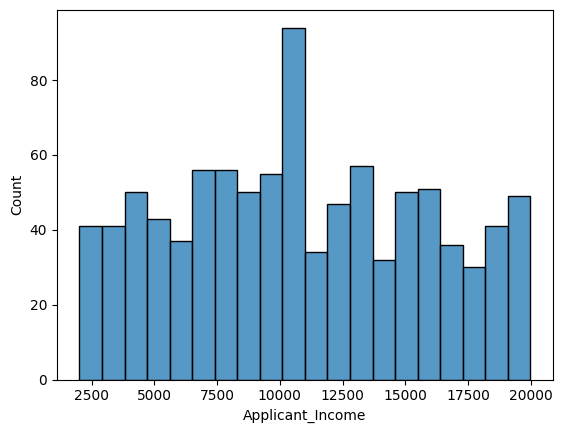

In [14]:

sns.histplot(
    data=df,
    x="Applicant_Income",
    bins=20
)
plt.show()

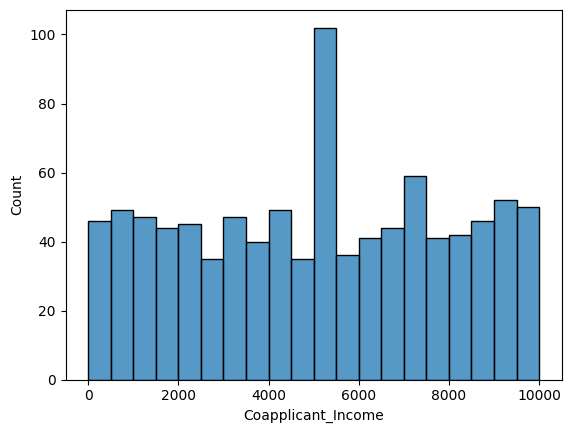

In [15]:
sns.histplot(
    data=df,
    x="Coapplicant_Income",
    bins=20
)
plt.show()

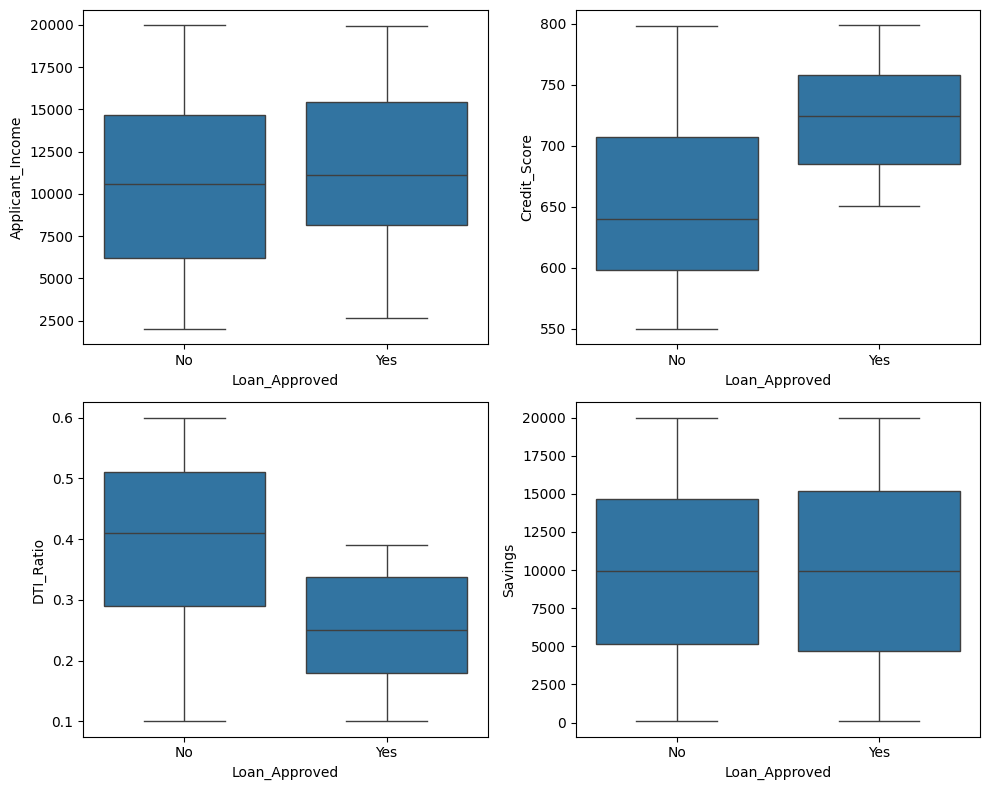

In [16]:

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.boxplot(ax=axes[0, 0], data=df, x="Loan_Approved", y="Applicant_Income")
sns.boxplot(ax=axes[0, 1], data=df, x="Loan_Approved", y="Credit_Score")
sns.boxplot(ax=axes[1, 0], data=df, x="Loan_Approved", y="DTI_Ratio")
sns.boxplot(ax=axes[1, 1], data=df, x="Loan_Approved", y="Savings")

plt.tight_layout()
plt.show()

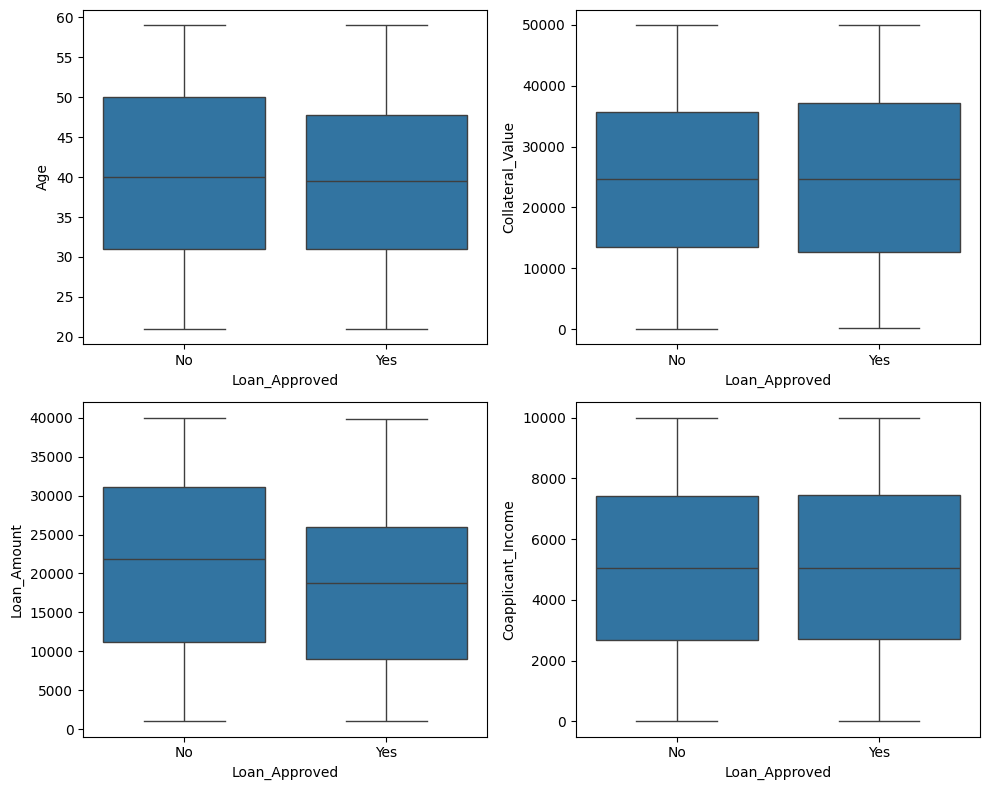

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.boxplot(ax=axes[0, 0], data=df, x="Loan_Approved", y="Age")
sns.boxplot(ax=axes[0, 1], data=df, x="Loan_Approved", y="Collateral_Value")
sns.boxplot(ax=axes[1, 0], data=df, x="Loan_Approved", y="Loan_Amount")
sns.boxplot(ax=axes[1, 1], data=df, x="Loan_Approved", y="Coapplicant_Income")

plt.tight_layout()
plt.show()

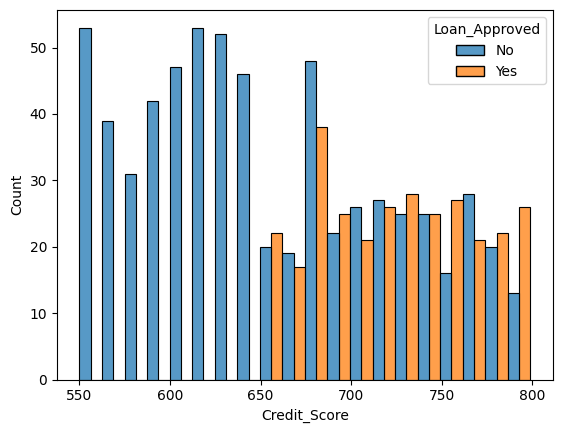

In [18]:

sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)
plt.show()

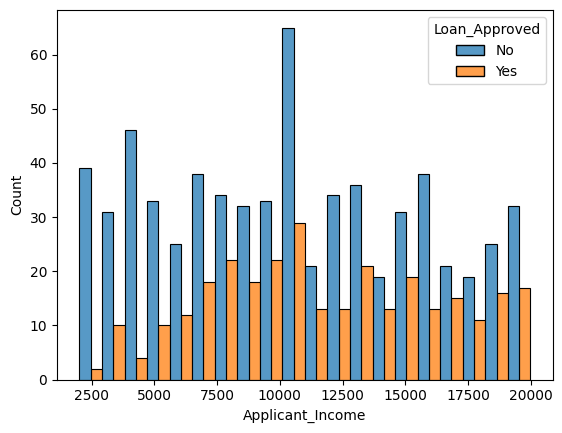

In [19]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)
plt.show()

In [20]:
df = df.drop("Applicant_ID", axis=1)

In [21]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# Encoding

In [22]:
df.info()

<class 'pandas.DataFrame'>
Index: 950 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    950 non-null    float64
 1   Coapplicant_Income  950 non-null    float64
 2   Employment_Status   950 non-null    str    
 3   Age                 950 non-null    float64
 4   Marital_Status      950 non-null    str    
 5   Dependents          950 non-null    float64
 6   Credit_Score        950 non-null    float64
 7   Existing_Loans      950 non-null    float64
 8   DTI_Ratio           950 non-null    float64
 9   Savings             950 non-null    float64
 10  Collateral_Value    950 non-null    float64
 11  Loan_Amount         950 non-null    float64
 12  Loan_Term           950 non-null    float64
 13  Loan_Purpose        950 non-null    str    
 14  Property_Area       950 non-null    str    
 15  Education_Level     950 non-null    str    
 16  Gender              950 

In [23]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le_edu = LabelEncoder()
df["Education_Level"] = le_edu.fit_transform(df["Education_Level"])

le_target = LabelEncoder()
df["Loan_Approved"] = le_target.fit_transform(df["Loan_Approved"])

print("Loan_Approved mapping:", dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))

Loan_Approved mapping: {'No': np.int64(0), 'Yes': np.int64(1)}


In [24]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [25]:

cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Gender", "Employer_Category"]

ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(encoded, columns=ohe.get_feature_names_out(cols), index=df.index)

df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)

In [26]:
df.head()
df.info()

<class 'pandas.DataFrame'>
Index: 950 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 950 non-null    float64
 1   Coapplicant_Income               950 non-null    float64
 2   Age                              950 non-null    float64
 3   Dependents                       950 non-null    float64
 4   Credit_Score                     950 non-null    float64
 5   Existing_Loans                   950 non-null    float64
 6   DTI_Ratio                        950 non-null    float64
 7   Savings                          950 non-null    float64
 8   Collateral_Value                 950 non-null    float64
 9   Loan_Amount                      950 non-null    float64
 10  Loan_Term                        950 non-null    float64
 11  Education_Level                  950 non-null    int64  
 12  Loan_Approved                    950 n

# Correlation Heatmap

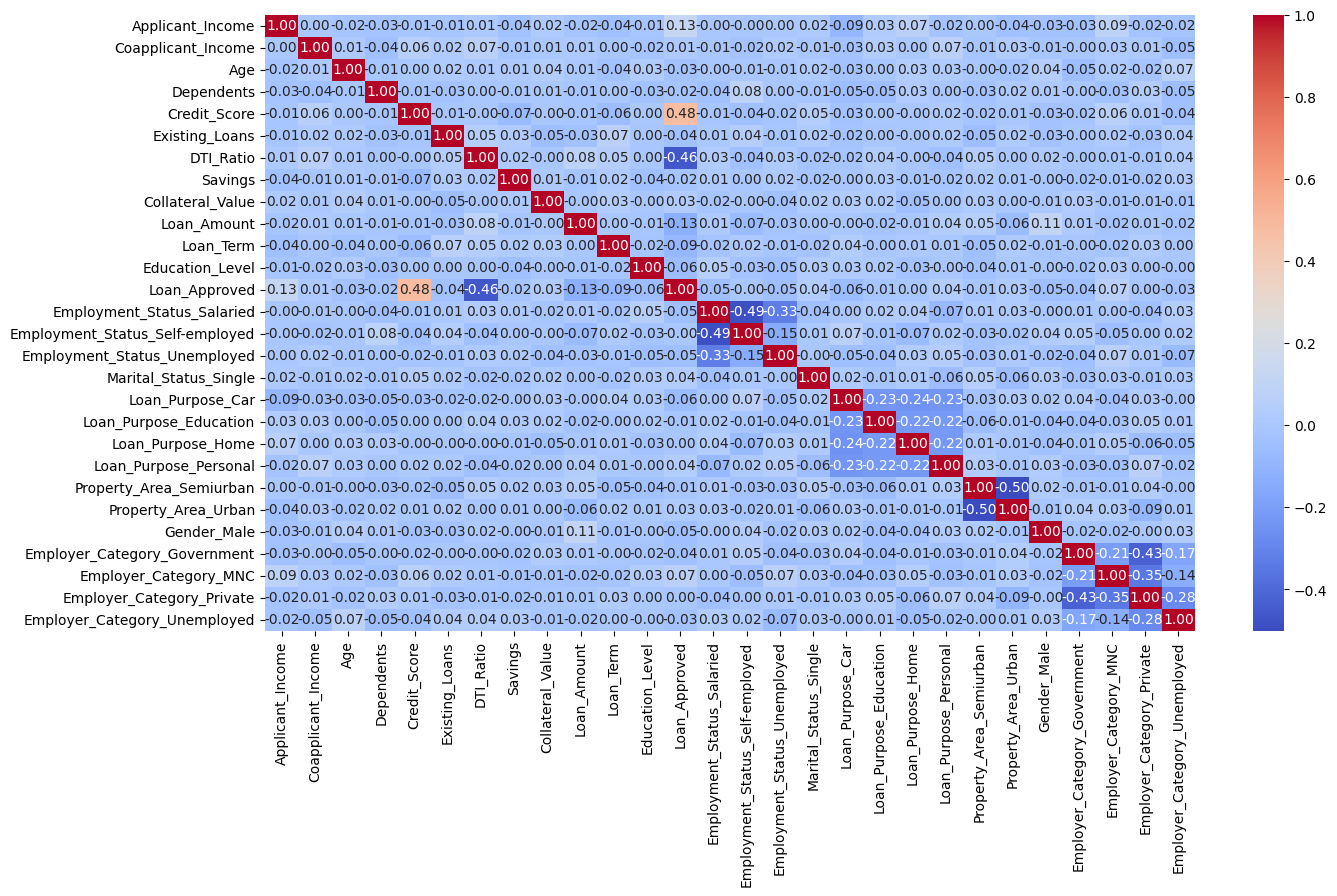

In [27]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.show()

In [28]:
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.476911
Applicant_Income                   0.125010
Employer_Category_MNC              0.073448
Marital_Status_Single              0.037586
Loan_Purpose_Personal              0.035519
Collateral_Value                   0.027350
Property_Area_Urban                0.025731
Coapplicant_Income                 0.009127
Loan_Purpose_Home                  0.003108
Employer_Category_Private          0.000707
Employment_Status_Self-employed   -0.001572
Loan_Purpose_Education            -0.011940
Property_Area_Semiurban           -0.014259
Dependents                        -0.016199
Savings                           -0.016857
Age                               -0.027393
Employer_Category_Unemployed      -0.028736
Existing_Loans                    -0.035384
Employer_Category_Government      -0.039135
Employment_Status_Salaried        -0.046912
Employment_Status_Unemployed      -0.047256
Gender_Male                     

# Train-Test-Split + Feature Scaling

In [29]:
X = df.drop("Loan_Approved", axis=1)
y = df["Loan_Approved"]

In [30]:
y.head()

0    0
1    0
2    1
3    0
4    1
Name: Loan_Approved, dtype: int64

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [32]:
X_test.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
153,7791.0,7138.0,47.0,2.0,775.0,1.0,0.28,9966.298557,23949.0,21505.000000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
664,10150.0,6924.0,57.0,1.0,669.0,1.0,0.39,9884.000000,17718.0,11528.000000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
376,18347.0,7424.0,35.0,3.0,589.0,1.0,0.53,19464.000000,2036.0,28621.000000,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
890,13694.0,8453.0,50.0,0.0,797.0,4.0,0.24,9877.000000,49116.0,20455.895903,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
589,10427.0,2203.0,27.0,3.0,784.0,1.0,0.19,9966.298557,2611.0,8878.000000,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0


In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [34]:
print("NaN in train:", np.isnan(X_train_scaled).sum(), "| NaN in test:", np.isnan(X_test_scaled).sum())

NaN in train: 0 | NaN in test: 0


# Train & Evaluate Models

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score


def evaluate(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    print(name)
    print("Precision: ", precision_score(y_test, y_pred))
    print("Recall: ", recall_score(y_test, y_pred))
    print("F1 score: ", f1_score(y_test, y_pred))
    print("Accuracy: ", accuracy_score(y_test, y_pred))
    print("CM: ", confusion_matrix(y_test, y_pred))
    print()

In [36]:
evaluate("Logistic Regression Model", LogisticRegression(), X_train_scaled, X_test_scaled)

Logistic Regression Model
Precision:  0.8181818181818182
Recall:  0.75
F1 score:  0.782608695652174
Accuracy:  0.868421052631579
CM:  [[120  10]
 [ 15  45]]



In [37]:

evaluate("KNN Model", KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled)

KNN Model
Precision:  0.625
Recall:  0.5833333333333334
F1 score:  0.603448275862069
Accuracy:  0.7578947368421053
CM:  [[109  21]
 [ 25  35]]



In [38]:
evaluate("Naive Bayes Model", GaussianNB(), X_train_scaled, X_test_scaled)

Naive Bayes Model
Precision:  0.8541666666666666
Recall:  0.6833333333333333
F1 score:  0.7592592592592593
Accuracy:  0.8631578947368421
CM:  [[123   7]
 [ 19  41]]



# Feature Engineering

In [39]:
df_fe = df.copy()

df_fe["DTI_Ratio_sq"] = df_fe["DTI_Ratio"] ** 2
df_fe["Credit_Score_sq"] = df_fe["Credit_Score"] ** 2

X = df_fe.drop(columns=["Loan_Approved", "Credit_Score", "DTI_Ratio"])
y = df_fe["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("NaN in train:", np.isnan(X_train_scaled).sum(), "| NaN in test:", np.isnan(X_test_scaled).sum())

NaN in train: 0 | NaN in test: 0


In [40]:
X_train.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Existing_Loans,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,...,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed,DTI_Ratio_sq,Credit_Score_sq
443,7486.0,9127.000000,38.0,3.000000,4.0,9966.298557,10265.0,36198.0,84.0,0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.067600,531441.0
212,7592.0,8202.000000,52.0,1.460687,3.0,16480.000000,22080.0,13204.0,48.0,0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.260100,305809.0
365,16069.0,3155.000000,47.0,2.000000,4.0,8708.000000,49163.0,29016.0,60.0,0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.120539,580644.0
783,7256.0,9654.000000,52.0,3.000000,0.0,3083.000000,2552.0,38981.0,12.0,0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.136900,528529.0
667,17745.0,5061.607539,27.0,3.000000,3.0,17042.000000,12342.0,8641.0,84.0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.220900,471969.0


In [41]:
evaluate("Logistic Regression Model", LogisticRegression(), X_train_scaled, X_test_scaled)

Logistic Regression Model
Precision:  0.8181818181818182
Recall:  0.75
F1 score:  0.782608695652174
Accuracy:  0.868421052631579
CM:  [[120  10]
 [ 15  45]]



In [42]:

evaluate("KNN Model", KNeighborsClassifier(n_neighbors=5), X_train_scaled, X_test_scaled)

KNN Model
Precision:  0.631578947368421
Recall:  0.6
F1 score:  0.6153846153846154
Accuracy:  0.7631578947368421
CM:  [[109  21]
 [ 24  36]]



In [43]:
evaluate("Naive Bayes Model", GaussianNB(), X_train_scaled, X_test_scaled)

Naive Bayes Model
Precision:  0.8148148148148148
Recall:  0.7333333333333333
F1 score:  0.7719298245614035
Accuracy:  0.8631578947368421
CM:  [[120  10]
 [ 16  44]]

